# Link communities — *Os Maias*

This notebook implements the unweighted link-clustering method of Ahn, Bagrow & Lehmann (2010), from scratch. After applying each co-occurrence weight threshold, weights are not used in link similarity or partition density. They are used for character strength, tables, and plotting. Each link belongs to exactly one dendrogram component; only components with at least three links count as reported communities, and smaller components are treated as unassigned for node-community metrics.

For adjacent links `i-k` and `j-k`, similarity is `S = |n+(i) ∩ n+(j)| / |n+(i) ∪ n+(j)|`, with `n+(x)` the inclusive neighborhood of `x`. The global partition density is `D = (2/M) Σ_c m_c [m_c - (n_c - 1)] / [(n_c - 2)(n_c - 1)]`; terms with `n_c <= 2` are zero. Similarities are computed only for link pairs sharing an endpoint, then processed in descending order by union-find. All equal-similarity merges are applied together before evaluating D.

The required adaptive-cut comparison follows Boucherie, Ahn & Lehmann (2026, [paper](https://arxiv.org/abs/2512.08741)). I read the [repository README](https://github.com/LCB0B/adaptive_cut#how-it-works) and its [`cut.py`](https://github.com/LCB0B/adaptive_cut/blob/main/src/adaptive_cut/cut.py), [`_kernels.py`](https://github.com/LCB0B/adaptive_cut/blob/main/src/adaptive_cut/_kernels.py), and [`link.py`](https://github.com/LCB0B/adaptive_cut/blob/main/src/adaptive_cut/link.py). This implementation adapts their tree-cut representation, best-single-level initialization, link partition-density temperature, and logarithmic cooling schedule. For fidelity to the course-task specification, its local moves are the specified one-merge up/down moves and its acceptance rule is `exp(dD/T)` without the paper/repository sampler's reversible-jump proposal correction; it is therefore a transparent simplified Metropolis walk, not a byte-for-byte reproduction of their RJMCMC.

## 1. Load the weighted graph and define reproducible settings

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

from communities import load_weighted_graph, threshold_graph
from link_communities import (
    ADAPTIVE_NULL_REPLICATES, ADAPTIVE_NULL_SEED, ADAPTIVE_SEEDS,
    ADAPTIVE_STEPS, ADAPTIVE_WALK_SEED, DEFAULT_NULL_REPLICATES,
    DEFAULT_NULL_SEED, DEFAULT_SWAPS_PER_EDGE, LABEL_SHUFFLE_SEED,
    LOUVAIN_SEEDS, LAYOUT_SEED,
    analyze_thresholds, character_community_table, cluster_links,
    community_link_table, community_table, compare_kclique_overlaps,
    compare_changed_communities, compare_with_louvain, compute_link_layout,
    create_output_dir, partition_density, plot_adaptive_comparison,
    plot_changed_communities, plot_density_sweep, plot_link_communities,
    plot_top_character_communities,
    recommend_setting, result_for_cut, run_adaptive_null,
    run_adaptive_sensitivity, summarize_adaptive_null,
    summarize_adaptive_partition, adaptive_setting_summary, validate_result,
)

ROOT = Path.cwd()
EDGE_PATH = ROOT / "Data" / "os_maias_cooccurrence_edges.csv"
NODE_PATH = ROOT / "Data" / "os_maias_ground_truth_nodes.csv"
G, name_map = load_weighted_graph(EDGE_PATH, NODE_PATH)
THRESHOLDS = (1, 2, 3)
OUTPUT_DIR = create_output_dir(ROOT, "link_communities_adaptive_outputs")
N_SHUFFLES = DEFAULT_NULL_REPLICATES  # 100 degree-preserving rewires per threshold
SWAPS_PER_EDGE = DEFAULT_SWAPS_PER_EDGE  # nswap = 10 * m
BASE_NULL_SEED = DEFAULT_NULL_SEED  # threshold offsets and replicate indices are fixed
N_ADAPTIVE_NULL = ADAPTIVE_NULL_REPLICATES  # 20 fully optimized rewires per threshold
print({"nodes": G.number_of_nodes(), "links": G.number_of_edges(),
       "thresholds": THRESHOLDS, "null replicates": N_SHUFFLES,
       "swaps per edge": SWAPS_PER_EDGE, "base null seed": BASE_NULL_SEED,
       "adaptive seeds": ADAPTIVE_SEEDS, "adaptive steps": ADAPTIVE_STEPS,
       "adaptive null replicates": N_ADAPTIVE_NULL, "output directory": OUTPUT_DIR})

{'nodes': 103, 'links': 663, 'thresholds': (1, 2, 3), 'null replicates': 100, 'swaps per edge': 10, 'base null seed': 4200, 'adaptive seeds': (0, 1, 2, 3, 4, 5, 6, 7), 'adaptive steps': 5000, 'adaptive null replicates': 20, 'output directory': WindowsPath('c:/Users/lenovo/OneDrive/Documentos/Uni/DTU - Master in Business Analytics/Social Graphs/SGI-Project/link_communities_adaptive_outputs_4')}


## 2. Validate the exercise 4.8 example and the edge partition

In [11]:
toy = nx.Graph()
toy.add_edges_from([
    ("A", "B"), ("A", "C"), ("B", "C"),
    ("C", "D"), ("C", "E"), ("D", "E"), ("A", "F"),
])
toy_result = cluster_links(toy)
expected = {
    frozenset({("A", "B"), ("A", "C"), ("B", "C")}),
    frozenset({("C", "D"), ("C", "E"), ("D", "E")}),
    frozenset({("A", "F")}),
}
assert {frozenset(group) for group in toy_result["communities"]} == expected
assert len(toy_result["membership"]["C"]) == 2
assert len(toy_result["membership"]["F"]) == 1
assert validate_result(toy_result)
print("Exercise 4.8 toy communities:", toy_result["communities"])
print("C memberships:", toy_result["membership"]["C"],
      "| F memberships:", toy_result["membership"]["F"])
print("Toy D at selected cut:", toy_result["best_partition_density"])

Exercise 4.8 toy communities: [[('A', 'B'), ('A', 'C'), ('B', 'C')], [('C', 'D'), ('C', 'E'), ('D', 'E')], [('A', 'F')]]
C memberships: [1, 2] | F memberships: [3]
Toy D at selected cut: 0.8571428571428571


## 3. Choose each cut by maximum D and test against degree-preserving nulls

At each threshold, the 100 null graphs are generated once using `nx.double_edge_swap`, with exactly `10*m` swaps per replicate. Seeds are `4200 + 100000 * threshold_index + replicate_index` (replicate indices start at zero). Each null graph is clustered once, and its maximum D, real-community count, overlap count, and mean real-community memberships per covered node are reused for all four metric tests. The reported p-value is two-sided with a +1 correction; the upper-tail p-value is also shown for the primary D* test. The z-score is NaN when the null standard deviation is zero. D* upper-tail p-values are Bonferroni-adjusted across the three thresholds.

In [12]:
summary, results, null_distributions = analyze_thresholds(
    G, thresholds=THRESHOLDS, n_shuffles=N_SHUFFLES,
    swaps_per_edge=SWAPS_PER_EDGE, seed=BASE_NULL_SEED,
)
for threshold in THRESHOLDS:
    assert validate_result(results[threshold])
    direct_D = partition_density(results[threshold]["communities"],
                                 len(results[threshold]["links"]))
    assert np.isclose(direct_D, results[threshold]["best_partition_density"])
summary.to_csv(OUTPUT_DIR / "link_communities_results.csv", index=False)
for threshold in THRESHOLDS:
    result = results[threshold]
    pd.DataFrame([
        {"link_id": i, "source": u, "target": v}
        for i, (u, v) in enumerate(result["links"])
    ]).to_csv(OUTPUT_DIR / f"link_communities_links_w{threshold}.csv", index=False)
    result["merges"].to_csv(OUTPUT_DIR / f"link_communities_merges_w{threshold}.csv", index=False)
    result["density_curve"].to_csv(OUTPUT_DIR / f"link_communities_density_w{threshold}.csv", index=False)
print("Saved result, leaf-link, merge-log and D-curve CSVs to", OUTPUT_DIR)
display(summary.round(4))

w_min=1: clustering 663 links; generating 100 null graphs


  analyzed null graph 10/100
  analyzed null graph 20/100
  analyzed null graph 30/100
  analyzed null graph 40/100
  analyzed null graph 50/100
  analyzed null graph 60/100
  analyzed null graph 70/100
  analyzed null graph 80/100
  analyzed null graph 90/100
  analyzed null graph 100/100
w_min=2: clustering 472 links; generating 100 null graphs
  analyzed null graph 10/100
  analyzed null graph 20/100
  analyzed null graph 30/100
  analyzed null graph 40/100
  analyzed null graph 50/100
  analyzed null graph 60/100
  analyzed null graph 70/100
  analyzed null graph 80/100
  analyzed null graph 90/100
  analyzed null graph 100/100
w_min=3: clustering 343 links; generating 100 null graphs
  analyzed null graph 10/100
  analyzed null graph 20/100
  analyzed null graph 30/100
  analyzed null graph 40/100
  analyzed null graph 50/100
  analyzed null graph 60/100
  analyzed null graph 70/100
  analyzed null graph 80/100
  analyzed null graph 90/100
  analyzed null graph 100/100
Saved resul

,w_min,nodes,links,similarity_pairs,D_star,cut_similarity,num_communities,links_in_real_pct,covered_nodes,overlap_nodes,...,overlap_nodes_null_std,overlap_nodes_z_score,overlap_nodes_p_value,overlap_nodes_p_upper,mean_communities_per_covered_node_null_mean,mean_communities_per_covered_node_null_std,mean_communities_per_covered_node_z_score,mean_communities_per_covered_node_p_value,mean_communities_per_covered_node_p_upper,D_star_p_upper_adjusted
0,1,103,663,17294,0.3342,0.4524,39,92.1569,93,57,...,3.5363,7.6550,0.0198,0.0099,3.3618,0.4143,-0.7435,0.5149,0.7525,0.0297
1,2,103,472,10439,0.2725,0.3662,17,90.6780,76,31,...,4.3923,1.0792,0.3960,0.1980,2.7193,0.4039,-2.1717,0.0594,0.9802,0.0297
2,3,103,343,6622,0.3394,0.4884,16,72.0117,42,30,...,3.8341,2.5717,0.0396,0.0198,2.2986,0.4591,1.0610,0.3168,0.1584,0.0297


## 4. Select and justify a setting

A candidate must be above the degree-preserving null after Bonferroni correction (`p_upper <= .05`), cover at least half the thresholded links in real communities, and avoid one community containing more than half of all links. Among candidates, the highest D* is selected. If none meets every condition, the fallback prioritizes adjusted null evidence, then D* and coverage; the choice is explicitly exploratory rather than a claim of a uniquely correct threshold.

In [13]:
W_MIN, recommendation_reason = recommend_setting(summary)
best = summary.loc[summary["w_min"] == W_MIN].iloc[0]
highlight = summary.style.apply(
    lambda row: ["background-color: #d9ead3" if row["w_min"] == W_MIN else ""
                 for _ in row], axis=1
).format(precision=3)
display(highlight)
print(f"Chosen w_min={W_MIN}: {recommendation_reason}.")
print(f"D*={best['D_star']:.3f}; adjusted upper-tail p={best['D_star_p_upper_adjusted']:.3f}; "
      f"real-link coverage={best['links_in_real_pct']:.1f}%; "
      f"largest community share={best['largest_community_link_fraction']:.1%}.")
print(f"Small clusters (<3 links): {int(best['small_community_links'])} links, "
      f"{int(best['small_community_nodes'])} distinct characters; "
      f"{int(best['nodes_only_in_small_communities'])} characters occur only in them.")

,w_min,nodes,links,similarity_pairs,D_star,cut_similarity,num_communities,links_in_real_pct,covered_nodes,overlap_nodes,communities_per_overlap_node,mean_communities_per_covered_node,largest_community_link_fraction,small_community_count,small_community_links,small_community_nodes,nodes_only_in_small_communities,D_star_null_mean,D_star_null_std,D_star_z_score,D_star_p_value,D_star_p_upper,num_communities_null_mean,num_communities_null_std,num_communities_z_score,num_communities_p_value,num_communities_p_upper,overlap_nodes_null_mean,overlap_nodes_null_std,overlap_nodes_z_score,overlap_nodes_p_value,overlap_nodes_p_upper,mean_communities_per_covered_node_null_mean,mean_communities_per_covered_node_null_std,mean_communities_per_covered_node_z_score,mean_communities_per_covered_node_p_value,mean_communities_per_covered_node_p_upper,D_star_p_upper_adjusted
0,1,103,663,17294,0.334,0.452,39,92.157,93,57,4.351,3.054,0.468,45,52,58,10,0.235,0.019,5.105,0.020,0.010,34.210,4.687,1.022,0.455,0.228,29.930,3.536,7.655,0.020,0.010,3.362,0.414,-0.744,0.515,0.752,0.030
1,2,103,472,10439,0.272,0.366,17,90.678,76,31,3.065,1.842,0.686,36,44,52,18,0.228,0.026,1.742,0.020,0.010,22.210,4.293,-1.214,0.297,0.891,26.260,4.392,1.079,0.396,0.198,2.719,0.404,-2.172,0.059,0.980,0.030
2,3,103,343,6622,0.339,0.488,16,72.012,42,30,3.500,2.786,0.335,80,96,71,39,0.213,0.023,5.403,0.020,0.010,15.260,3.971,0.186,0.871,0.436,20.140,3.834,2.572,0.040,0.020,2.299,0.459,1.061,0.317,0.158,0.030


Chosen w_min=3: selected among thresholds with Bonferroni-adjusted upper-tail p <= 0.05, at least 50% real-community link coverage, and no community holding more than half of all links; highest D* among those candidates.
D*=0.339; adjusted upper-tail p=0.030; real-link coverage=72.0%; largest community share=33.5%.
Small clusters (<3 links): 96 links, 71 distinct characters; 39 characters occur only in them.


## 5. Partition-density curves and null reference

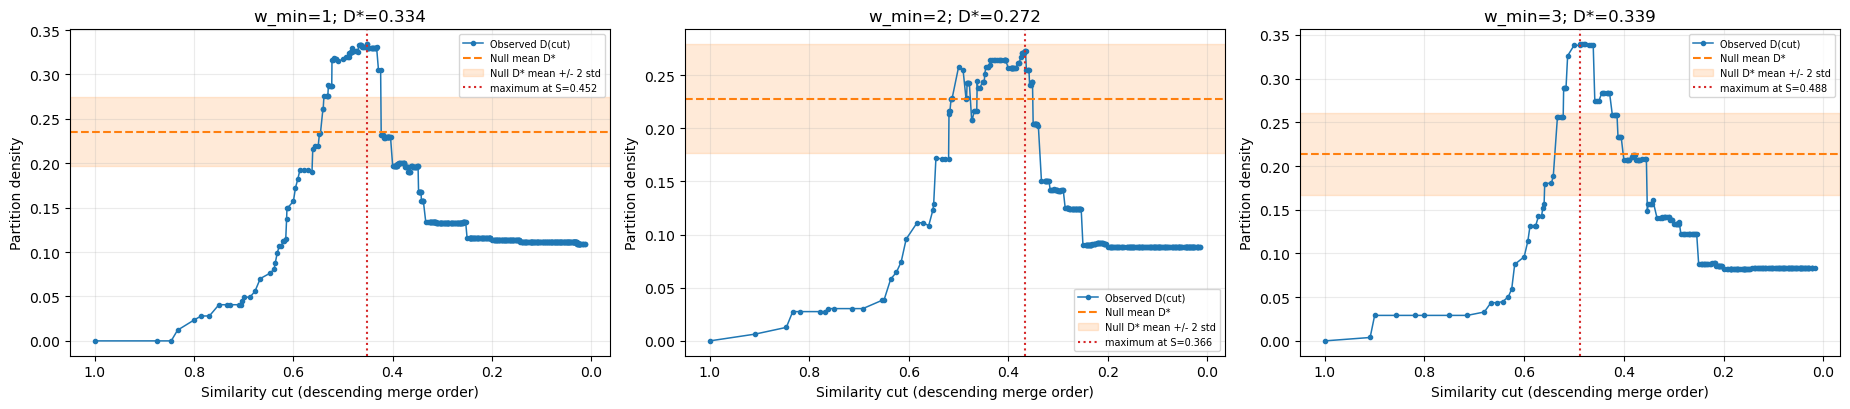

In [14]:
fig, axes = plot_density_sweep(summary, results, null_distributions)
plt.show()

The orange band is the null distribution's **optimized D*** mean +/- two standard deviations, shown as a horizontal reference; it is not the null D(cut) distribution at each exact observed similarity level. The red vertical marker identifies the observed cut selected by maximizing D.

## 6. Adaptive cut: seed and temperature sensitivity

The tree stores every merge node, its two children, similarity height, and link set; disconnected similarity components remain separate roots. Every walk starts from the maximum-D single-height cut. Eight paired seeds (0-7) are run for each of three configurations (`cold`, `auto`, `hot`), 5,000 proposals each. `auto` follows the repository's link-specific `clip(0.1/M * f_D, 1e-8, 1e-3)` temperature with a two-thirds plateau then logarithmic cooling; `cold` uses 0.1x T and begins cooling after one-quarter, while `hot` uses 100x T with the two-thirds plateau. Setting selection is per threshold: maximize median D across seeds after excluding configurations where >=50% of final walks have <=2 clusters or median proposal acceptance is <1%; if none remain, select by median D and flag the issue.

In [15]:
adaptive_runs, adaptive_walks = run_adaptive_sensitivity(
    results, seeds=ADAPTIVE_SEEDS, n_steps=ADAPTIVE_STEPS,
    seed=ADAPTIVE_WALK_SEED,
)
setting_summary = adaptive_setting_summary(adaptive_runs)
adaptive_runs.to_csv(OUTPUT_DIR / "adaptive_temperature_runs.csv", index=False)
display(setting_summary.round(4))

w_min=1: completed 24 adaptive sensitivity walks
w_min=2: completed 24 adaptive sensitivity walks
w_min=3: completed 24 adaptive sensitivity walks


,w_min,setting,D_min,D_median,D_max,median_D_gain,median_acceptance_rate,final_collapse_rate,too_warm,too_cold
0,1,auto,0.3479,0.3479,0.3516,0.0138,0.3209,0.000,False,False
1,1,cold,0.3479,0.3498,0.3516,0.0156,0.3095,0.000,False,False
2,1,hot,0.3342,0.3388,0.3403,0.0046,0.5186,0.000,False,False
3,2,auto,0.2836,0.2836,0.2839,0.0111,0.2413,0.000,False,False
4,2,cold,0.2836,0.2836,0.2836,0.0111,0.2261,0.000,False,False
5,2,hot,0.2725,0.2750,0.2803,0.0026,0.9327,0.875,True,False
6,3,auto,0.3647,0.3647,0.3647,0.0253,0.4046,0.000,False,False
7,3,cold,0.3647,0.3647,0.3647,0.0253,0.3741,0.000,False,False
8,3,hot,0.3394,0.3542,0.3610,0.0148,0.9278,0.500,True,False


In [16]:
adaptive_rows = []
adaptive_partitions = {}
for w_min in THRESHOLDS:
    row, partition = summarize_adaptive_partition(
        results[w_min], adaptive_runs[adaptive_runs["w_min"] == w_min],
        adaptive_walks, w_min,
    )
    adaptive_rows.append(row)
    adaptive_partitions[w_min] = partition
adaptive_summary = pd.DataFrame(adaptive_rows)
display(adaptive_summary.round(4))

,w_min,single_D,adaptive_D_median,adaptive_D_min,adaptive_D_max,adaptive_representative_D,adaptive_setting,representative_seed,single_communities,adaptive_communities,single_links_in_real_pct,adaptive_links_in_real_pct,single_covered_nodes,adaptive_covered_nodes,single_overlap_nodes,adaptive_overlap_nodes,adaptive_communities_per_overlap_node,setting_selection_rule
0,1,0.3342,0.3498,0.3479,0.3516,0.3479,cold,6200,39,39,92.1569,94.7210,93,99,57,58,4.1897,highest median D across 8 seeds; exclude setti...
1,2,0.2725,0.2836,0.2836,0.2839,0.2836,auto,106200,17,18,90.6780,91.3136,76,78,31,32,2.9688,highest median D across 8 seeds; exclude setti...
2,3,0.3394,0.3647,0.3647,0.3647,0.3647,auto,206200,16,26,72.0117,86.8805,42,68,30,42,3.4762,highest median D across 8 seeds; exclude setti...


## 7. Optimize the null in the same way

Use 20 degree-preserving shuffles per threshold (each with `nswap=10*m`). To match the observed optimization and temperature-selection rule, each null graph also gets all 3 settings x 8 seeds x 5,000 steps; choose its setting by the same median-D and stability rule, and use that setting's median best-D as its null statistic. Thus the null is optimized too; it is not the single-level D* null from above. Graph seeds are `ADAPTIVE_NULL_SEED + 100000*w_min + replicate`; walk seeds start at `ADAPTIVE_WALK_SEED + 1000000 + 100000*w_min` with disjoint replicate/setting/seed offsets.

In [17]:
adaptive_nulls = {}
adaptive_null_rows = []
for w_min in THRESHOLDS:
    null = run_adaptive_null(
        G, w_min, n_shuffles=N_ADAPTIVE_NULL, seeds=ADAPTIVE_SEEDS,
        n_steps=ADAPTIVE_STEPS,
        shuffle_seed=ADAPTIVE_NULL_SEED + w_min * 100_000,
        walk_seed=ADAPTIVE_WALK_SEED + 1_000_000 + w_min * 100_000,
    )
    adaptive_nulls[w_min] = null
    null.to_csv(OUTPUT_DIR / f"adaptive_null_w{w_min}.csv", index=False)
    observed = adaptive_summary.loc[
        adaptive_summary["w_min"] == w_min, "adaptive_D_median"
    ].iloc[0]
    adaptive_null_rows.append(
        summarize_adaptive_null(observed, null)
    )
adaptive_summary = pd.concat(
    [adaptive_summary, pd.DataFrame(adaptive_null_rows)], axis=1
)
adaptive_summary.to_csv(OUTPUT_DIR / "adaptive_cut_comparison.csv", index=False)
display(adaptive_summary.round(4))

  w_min=1: optimized null graph 5/20
  w_min=1: optimized null graph 10/20
  w_min=1: optimized null graph 15/20
  w_min=1: optimized null graph 20/20
  w_min=2: optimized null graph 5/20
  w_min=2: optimized null graph 10/20
  w_min=2: optimized null graph 15/20
  w_min=2: optimized null graph 20/20
  w_min=3: optimized null graph 5/20
  w_min=3: optimized null graph 10/20
  w_min=3: optimized null graph 15/20
  w_min=3: optimized null graph 20/20


,w_min,single_D,adaptive_D_median,adaptive_D_min,adaptive_D_max,adaptive_representative_D,adaptive_setting,representative_seed,single_communities,adaptive_communities,...,adaptive_covered_nodes,single_overlap_nodes,adaptive_overlap_nodes,adaptive_communities_per_overlap_node,setting_selection_rule,adaptive_null_replicates,adaptive_null_mean,adaptive_null_q025,adaptive_null_q975,adaptive_null_p_upper
0,1,0.3342,0.3498,0.3479,0.3516,0.3479,cold,6200,39,39,...,99,57,58,4.1897,highest median D across 8 seeds; exclude setti...,20,0.2438,0.2122,0.2737,0.0476
1,2,0.2725,0.2836,0.2836,0.2839,0.2836,auto,106200,17,18,...,78,31,32,2.9688,highest median D across 8 seeds; exclude setti...,20,0.2320,0.1465,0.2663,0.0476
2,3,0.3394,0.3647,0.3647,0.3647,0.3647,auto,206200,16,26,...,68,30,42,3.4762,highest median D across 8 seeds; exclude setti...,20,0.2218,0.1766,0.2684,0.0476


A chosen adaptive D is the median of the eight best-so-far chain values for the selected setting. The representative partition used in the network figure is the seed closest to that median. The p-value is the upper-tail estimate `(1 + # null D >= observed D)/(20 + 1)`; the displayed null interval is its 2.5th-97.5th percentile range.

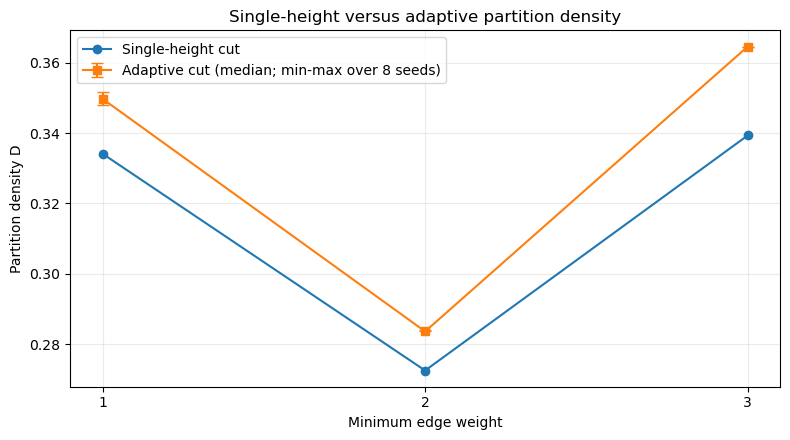

In [18]:
fig, ax = plot_adaptive_comparison(adaptive_summary)
plt.show()

## 6. Communities, memberships, and character bridges at the chosen threshold

In [19]:
H = threshold_graph(G, W_MIN)
single_result = results[W_MIN]
result = adaptive_partitions[W_MIN]
community_summary = community_table(H, result, name_map)
link_table = community_link_table(H, result, name_map)
adaptive_membership_table = pd.DataFrame(
    [
        {
            "community": community_id,
            "character_id": node,
            "character": name_map.get(node, node),
            "is_overlap": len(result["real_membership"].get(node, [])) > 1,
        }
        for community_id, nodes in enumerate(
            result["real_node_communities"], start=1
        )
        for node in sorted(nodes, key=lambda node: name_map.get(node, node).casefold())
    ],
    columns=["community", "character_id", "character", "is_overlap"],
)
community_summary.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_adaptive_communities.csv", index=False)
adaptive_membership_path = OUTPUT_DIR / f"link_communities_w{W_MIN}_adaptive_memberships.csv"
adaptive_membership_table.to_csv(adaptive_membership_path, index=False)
link_table.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_adaptive_links.csv", index=False)
display(community_summary)
display(
    adaptive_membership_table.sort_values(["community", "character"])
    .reset_index(drop=True)
)
display(link_table.head(15))
adaptive_link_path = OUTPUT_DIR / f"link_communities_w{W_MIN}_adaptive_links.csv"
print(f"Adaptive character-membership CSV: {adaptive_membership_path}")
print(f"Long-form adaptive link CSV: {adaptive_link_path}")

,community,number of links,number of nodes,top characters by weighted degree,overlap characters,strongest character
0,1,13,6,"Rosa, Miss Sara, Melanie, Niniche, Domingos","Rosa, Miss Sara, Melanie, Niniche, Domingos, J...",Rosa
1,2,6,4,"Maria Monforte, Pedro da Maia, Manuel Monforte...","Maria Monforte, Pedro da Maia, Manuel Monforte...",Maria Monforte
2,3,3,3,"Gonçalo, Neves, Sousa Neto","Gonçalo, Neves, Sousa Neto",Gonçalo
3,4,4,5,"Darque, Craft, Conde de Gouvarinho, Taveira, S...","Darque, Craft, Conde de Gouvarinho, Taveira, S...",Darque
4,5,4,4,"Carlos da Maia, Darque, Teles da Gama, João da...","Carlos da Maia, Darque, Teles da Gama, João da...",Carlos da Maia
5,6,6,6,"Palma Cavalão, Eusebiozinho Silveira, Lola, Cr...","Palma Cavalão, Eusebiozinho Silveira, Lola, Cr...",Palma Cavalão
6,7,5,5,"Palma Cavalão, Carlos da Maia, Lola, Dâmaso Sa...","Palma Cavalão, Carlos da Maia, Lola, Dâmaso Sa...",Palma Cavalão
7,8,3,4,"Reverendo Bonifácio, João da Ega, Carlos da Ma...","João da Ega, Carlos da Maia, Dâmaso Salcede",Reverendo Bonifácio
8,9,115,18,"Carlos da Maia, João da Ega, Dâmaso Salcede, M...","Carlos da Maia, João da Ega, Dâmaso Salcede, M...",Carlos da Maia
9,10,28,13,"Carlos da Maia, Joaquim Álvares de Castro Gome...","Carlos da Maia, Joaquim Álvares de Castro Gome...",Carlos da Maia


,community,character_id,character,is_overlap
0,1,domingos,Domingos,True
1,1,joaquim_alvares_castro_gomes,Joaquim Álvares de Castro Gomes,True
2,1,melanie,Melanie,True
3,1,miss_sara,Miss Sara,True
4,1,niniche,Niniche,True
...,...,...,...,...
167,26,carlos_maia,Carlos da Maia,True
168,26,encarnacion,Encarnación,False
169,26,mendonça,Mendonça,False
170,26,mae_cruges,Mãe Cruges,False


,community,link source,link target,weight
0,1,Domingos,Melanie,7.0
1,1,Domingos,Miss Sara,5.0
2,1,Domingos,Niniche,4.0
3,1,Domingos,Rosa,6.0
4,1,Joaquim Álvares de Castro Gomes,Melanie,3.0
5,1,Joaquim Álvares de Castro Gomes,Niniche,3.0
6,1,Joaquim Álvares de Castro Gomes,Rosa,3.0
7,1,Melanie,Miss Sara,12.0
8,1,Melanie,Niniche,3.0
9,1,Melanie,Rosa,3.0


Adaptive character-membership CSV: c:\Users\lenovo\OneDrive\Documentos\Uni\DTU - Master in Business Analytics\Social Graphs\SGI-Project\link_communities_adaptive_outputs_4\link_communities_w3_adaptive_memberships.csv
Long-form adaptive link CSV: c:\Users\lenovo\OneDrive\Documentos\Uni\DTU - Master in Business Analytics\Social Graphs\SGI-Project\link_communities_adaptive_outputs_4\link_communities_w3_adaptive_links.csv


Spearman rho(degree, real-community count)=0.847 (non-isolated characters; raw counts tend to track degree).
Top 10 by number of communities:


,character,character_id,communities,degree,communities per link,weighted degree,overlap
0,Carlos da Maia,carlos_maia,14,62,0.225806,2313.0,True
1,João da Ega,joao_ega,11,42,0.261905,1523.0,True
2,Dâmaso Salcede,damaso_salcede,9,29,0.310345,593.0,True
3,Taveira,taveira,7,21,0.333333,211.0,True
4,Afonso da Maia,afonso_maia,6,32,0.187500,533.0,True
5,Maria Eduarda,maria_eduarda,5,23,0.217391,556.0,True
6,Craft,craft,5,22,0.227273,423.0,True
7,Tomás de Alencar,tomas_alencar,5,25,0.200000,301.0,True
8,Conde de Gouvarinho,conde_gouvarinho,5,20,0.250000,181.0,True
9,Pedro da Maia,pedro_maia,4,17,0.235294,196.0,True


Top 10 by communities per link (among covered, non-isolated characters):


,character,character_id,communities,degree,communities per link,weighted degree,overlap
41,D. Eugénia Silveira,eugenia_silveira,2,2,1.0,8.0,True
56,Encarnación,encarnacion,1,1,1.0,7.0,False
59,Vicente,vicente,1,1,1.0,5.0,False
60,André da Ega,andre_ega,1,1,1.0,3.0,False
61,Conde de Runa,conde_runa,1,1,1.0,3.0,False
62,Sebastião da Maia,sebastiao_maia,1,1,1.0,3.0,False
63,Augusta,augusta,1,1,1.0,3.0,False
64,Mendonça,mendonça,1,1,1.0,3.0,False
65,Mãe Cruges,mae_cruges,1,1,1.0,3.0,False
66,Padre Serafim,padre_serafim,1,1,1.0,3.0,False


Carlos da Maia: 14 real link communities
João da Ega: 11 real link communities
Afonso da Maia: 6 real link communities


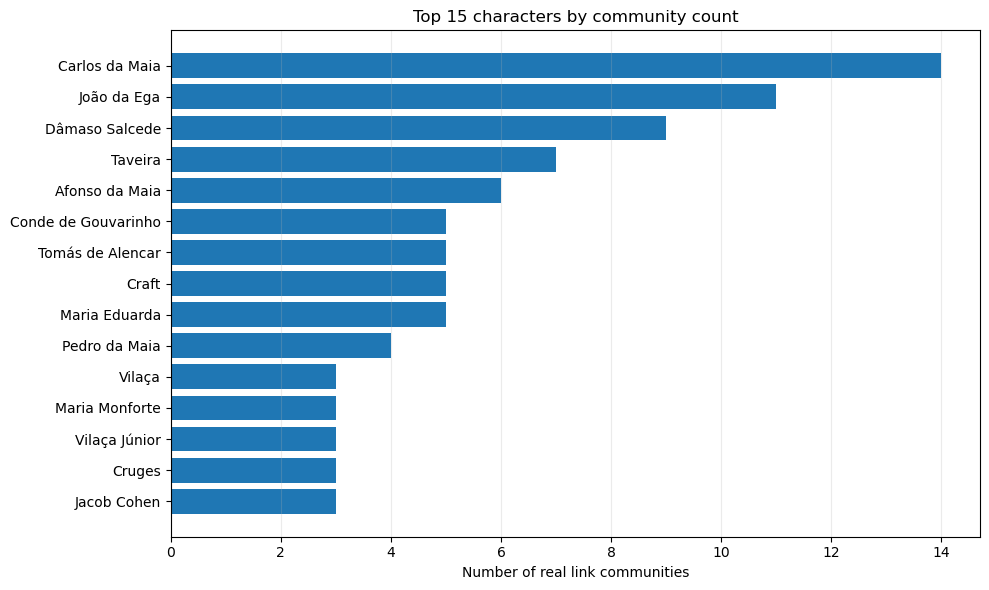

In [20]:
character_stats, degree_community_rho = character_community_table(H, result, name_map)
character_stats.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_adaptive_characters.csv", index=False)
print(f"Spearman rho(degree, real-community count)={degree_community_rho:.3f} "
      f"(non-isolated characters; raw counts tend to track degree).")
print("Top 10 by number of communities:")
display(character_stats[character_stats["communities"] > 0].head(10))
print("Top 10 by communities per link (among covered, non-isolated characters):")
ratio_top = character_stats[(character_stats["communities"] > 0) &
                            character_stats["communities per link"].notna()]
display(ratio_top.sort_values(["communities per link", "communities", "degree"],
                              ascending=[False, False, True]).head(10))
counts = character_stats.set_index("character")["communities"]
for character in ("Carlos da Maia", "João da Ega", "Afonso da Maia"):
    print(f"{character}: {int(counts.get(character, 0))} real link communities")
fig, ax = plot_top_character_communities(character_stats, top_n=15)
plt.show()

A node inherits memberships from all its incident links, but links in clusters smaller than three do not create reported memberships. The count is therefore the number of real link communities; communities-per-link divides that count by the character's unweighted degree in this thresholded graph. The ratio is more informative about how widely a character's ties are distributed, while the raw count is partly driven by having more links.

## 7. Network visualization

The deterministic layout uses seed 42 and is computed once here, then passed to the plotting helper. Characters outside the detected communities are placed near positioned neighbors; graph isolates are placed near the layout center rather than at force-layout corners.

In [21]:
long_df = pd.DataFrame(
    [
        {
            "community_id": community_id,
            "character_id": node,
            "character": name_map.get(node, node),
            "is_overlap": len(result["real_membership"].get(node, [])) > 1,
        }
        for community_id, nodes in enumerate(
            result["real_node_communities"], start=1
        )
        for node in sorted(nodes, key=lambda node: name_map.get(node, node).casefold())
    ],
    columns=["community_id", "character_id", "character", "is_overlap"],
)
display(
    long_df[["community_id", "character", "is_overlap"]]
    .sort_values(["community_id", "character"])
    .reset_index(drop=True)
)

,community_id,character,is_overlap
0,1,Domingos,True
1,1,Joaquim Álvares de Castro Gomes,True
2,1,Melanie,True
3,1,Miss Sara,True
4,1,Niniche,True
...,...,...,...
167,26,Carlos da Maia,True
168,26,Encarnación,False
169,26,Mendonça,False
170,26,Mãe Cruges,False


In [22]:
long_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172 entries, 0 to 171
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   community_id  172 non-null    int64 
 1   character_id  172 non-null    object
 2   character     172 non-null    object
 3   is_overlap    172 non-null    bool  
dtypes: bool(1), int64(1), object(2)
memory usage: 4.3+ KB


In [23]:
long_df[long_df["community_id"] == 15].reset_index()

,index,community_id,character_id,character,is_overlap
0,93,15,afonso_maia,Afonso da Maia,True
1,94,15,baptista,Baptista,True
2,95,15,carlos_maia,Carlos da Maia,True
3,96,15,conde_gouvarinho,Conde de Gouvarinho,True
4,97,15,damaso_salcede,Dâmaso Salcede,True
5,98,15,joaquim_alvares_castro_gomes,Joaquim Álvares de Castro Gomes,True
6,99,15,joao_ega,João da Ega,True
7,100,15,maria_eduarda,Maria Eduarda,True
8,101,15,tomas_alencar,Tomás de Alencar,True
9,102,15,vilaca_junior,Vilaça Júnior,True


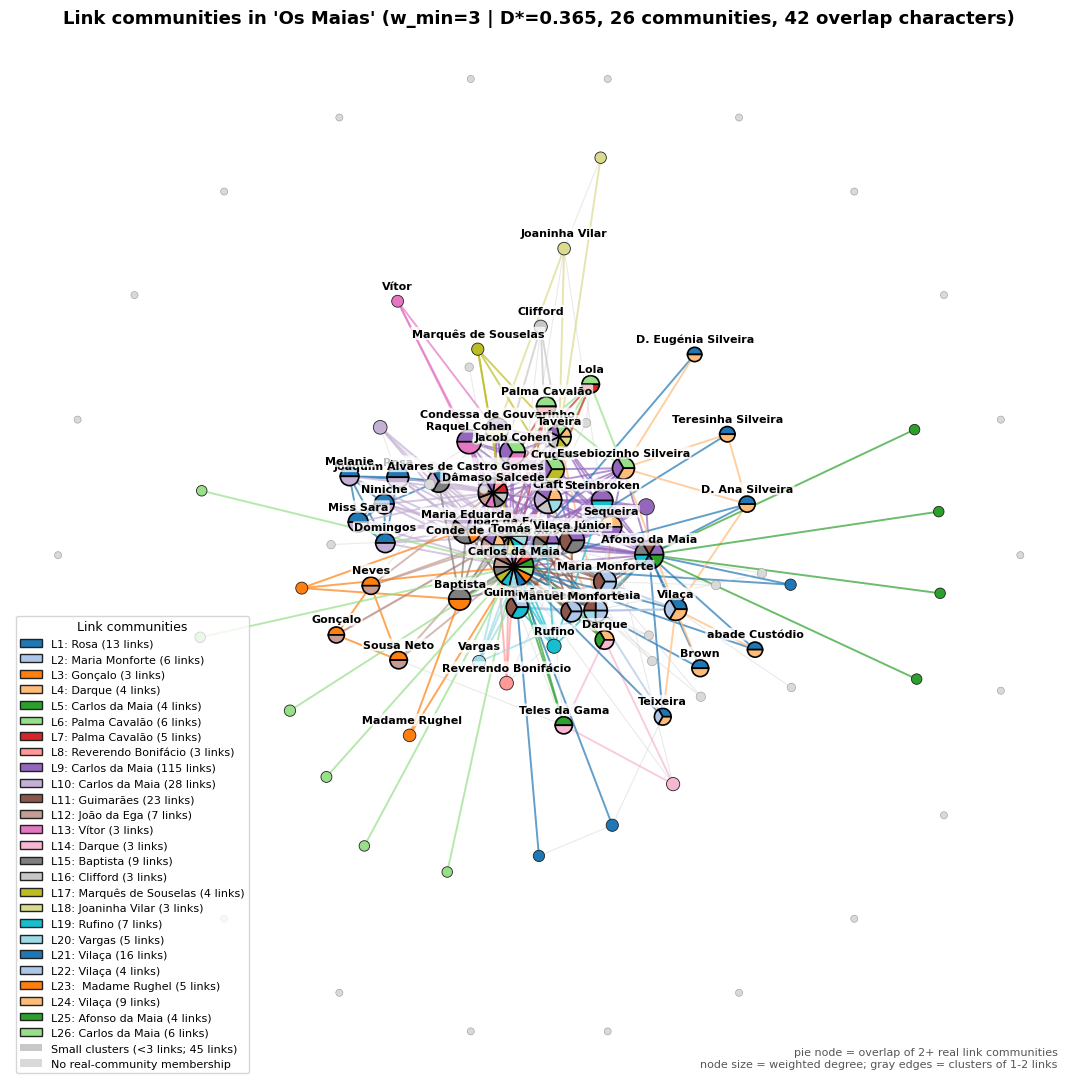

In [24]:
pos = compute_link_layout(H, result, seed=LAYOUT_SEED)
assert set(pos) == set(H.nodes)
fig, ax, pos = plot_link_communities(H, result, name_map, W_MIN, pos=pos)
plt.show()

## Adaptive versus single-height community memberships

The table lists real link clusters that changed: an adaptive merge combines multiple single-height branches; an adaptive split sends a single-height branch to multiple adaptive communities. Character names identify the members of each partition and are not, by themselves, evidence of narrative roles.

,change,single communities,adaptive communities,single link counts,adaptive link counts,single members,adaptive members,links affected
0,adaptive merge,"S17, S18, S22, S24, S33, S36, S39, S41, S52, S...",A51,"2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1",16,"abade Custódio, Afonso da Maia, Brown, Carlos ...","abade Custódio, Afonso da Maia, Brown, Carlos ...",16
1,adaptive split,S5,"A31, A33",10,"4, 4","Carlos da Maia, Conde de Gouvarinho, Craft, Da...","Conde de Gouvarinho, Craft, Darque, Sequeira, ...",10
2,adaptive merge,"S6, S46",A44,"8, 1",9,"Afonso da Maia, Baptista, Carlos da Maia, Cond...","Afonso da Maia, Baptista, Carlos da Maia, Cond...",9
3,adaptive merge,"S19, S23, S42, S43, S75, S76, S96",A55,"2, 2, 1, 1, 1, 1, 1",9,"abade Custódio, Brown, D. Ana Silveira, D. Eug...","abade Custódio, Brown, D. Ana Silveira, D. Eug...",9


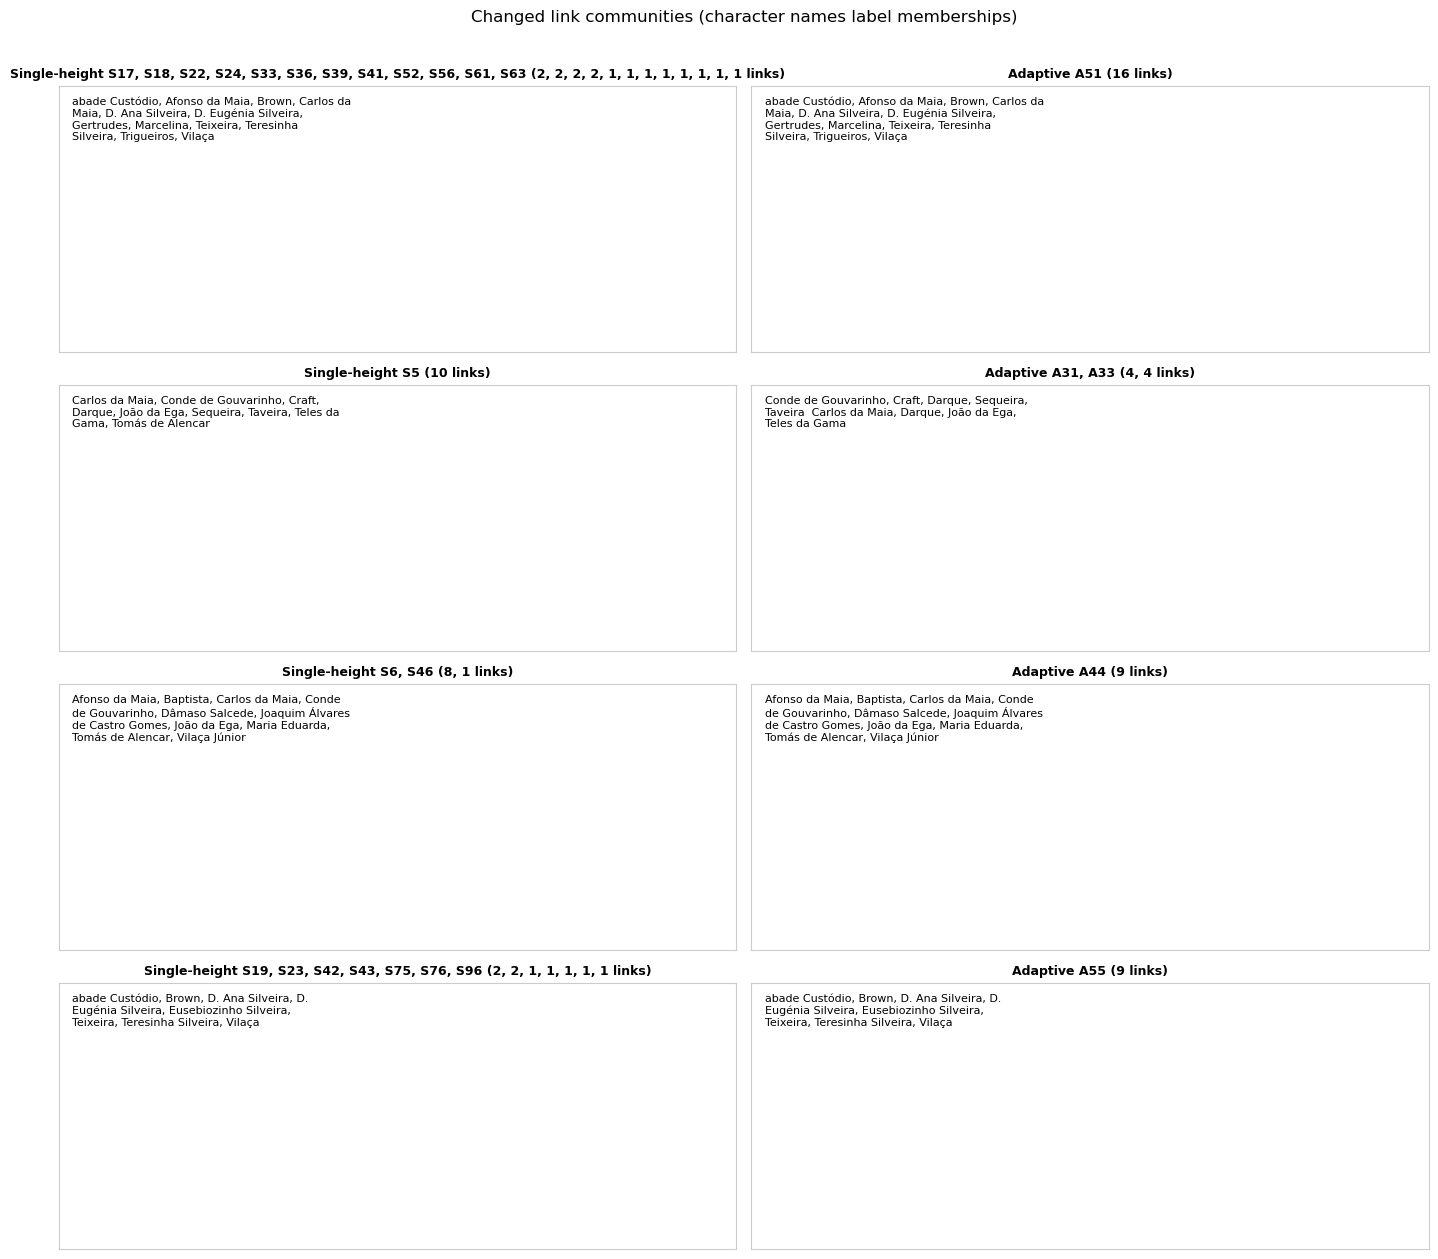

In [25]:
changed_communities = compare_changed_communities(
    single_result, result, name_map, max_examples=3
)
changed_communities.to_csv(
    OUTPUT_DIR / f"link_communities_w{W_MIN}_changed_communities.csv", index=False
)
display(changed_communities)
fig, axes = plot_changed_communities(changed_communities)
plt.show()

### Interpretation of the adaptive partition

At the selected `w_min=1`, the cold setting has median adaptive D*=0.3498 across eight seeds (range 0.3479-0.3516), versus 0.3342 for the single-height cut. Its 20 optimized nulls have mean D*=0.2438, a 2.5-97.5% range of 0.2122-0.2737, and an upper-tail +1 corrected p=0.0476. Real-link coverage rises from 92.2% to 94.7%, with 39 reported communities in both cuts; the largest adaptive community has 310/663 links (46.8%).

The member comparison shows S2 and S9 joining as A60 (64 links), S3 and S14 joining as A63 (25 links), and S5 splitting into 12- and 4-link groups. For example, the S5 labels include Esteves, abade Custódio, Afonso da Maia, Carlos da Maia, D. Ana Silveira, D. Eugénia Silveira, and Jones Bule; the split is a structural difference, not evidence by itself of separate story contexts. These results support a higher-density, slightly broader assignment at this threshold, but do not establish that the adaptive groups are more meaningful for the novel without text-level reading. Names are partition labels, and all interpretation remains conditional on the co-occurrence network, threshold, and density objective.

## 8. Compare overlap characters with k-clique communities

In [26]:
overlap_comparison = compare_kclique_overlaps(
    G, result, name_map, settings=((5, 2), (8, 3))
)
display(overlap_comparison)

,comparison,link overlap nodes,k-clique overlap nodes,intersection,union,Jaccard,in both
0,"k=5, w_min=2",42,6,6,42,0.142857,"Afonso da Maia, Carlos da Maia, D. Ana Silveir..."
1,"k=8, w_min=3",42,6,6,42,0.142857,"Afonso da Maia, Carlos da Maia, Dâmaso Salcede..."


## 9. Compare with Louvain (hard-label sensitivity check)

Each covered character is assigned its dominant real link community: the community containing the largest number of its incident links (ties go to the lower community ID). Louvain is run five times with seeds 41–45 on the weighted threshold graph. The ceiling is mean pairwise NMI among those Louvain runs; the shuffled-label baseline uses 1,000 permutations and seed 5200.

In [27]:
louvain_summary, louvain_runs = compare_with_louvain(
    H, result, seeds=LOUVAIN_SEEDS, n_label_shuffles=1000,
    seed=LABEL_SHUFFLE_SEED,
)
display(louvain_summary)
display(louvain_runs)

,covered characters,link-vs-Louvain NMI mean,link-vs-Louvain NMI std,Louvain-vs-Louvain NMI ceiling,shuffled-label NMI mean,shuffled-label NMI std,shuffled-label p_upper
0,68,0.45962,0.008651,0.851374,0.280144,0.022625,0.000999


,seed,link-vs-Louvain NMI
0,41,0.462270
1,42,0.465499
2,43,0.465499
3,44,0.442560
4,45,0.462270


Link communities assign every link to a cluster, so they can organize sparse parts of the graph that k-clique percolation leaves uncovered. This implementation excludes one- and two-link clusters from real node memberships, but reports them as unassigned links/nodes. Conversely, node communities derived from links can group a character's ties by local context without requiring a dense node-induced clique. The Louvain comparison is only a hard-label simplification: dominant-community labels discard the overlap that link clustering is designed to preserve.

## How to read these results

`D*` is the maximum partition density across the single-linkage dendrogram, not a probability that a community is true. The orange reference shows the mean and +/-2 standard deviations of optimized D* from degree-preserving rewires; empirical p-values are preferable when the null standard deviation is tiny, and the adjusted D* p-value accounts for trying three thresholds. A high D* is most persuasive when it also exceeds the null, covers a reasonable share of links, and is not driven by one giant community. k-clique communities require dense, overlapping cliques and can leave sparse links uncovered; link communities cluster edges by similarity of their endpoint contexts and can cover those sparse regions, but the three-link reporting rule leaves many tiny clusters unassigned. The methods therefore answer related but different questions, and their overlap sets need not agree.